# Facebook Live Sellers: Engagement Analysis & K-Means Clustering

Exploratory analysis of ~7,000 Facebook Live posts from online sellers: how upload time affects reactions, how reactions, comments and shares relate, and how posts differ by type. Posts are then grouped by engagement with K-Means, using the elbow method to pick the number of clusters.

**Dataset:** `data/Facebook_Marketplace_data.csv`, based on the *Facebook Live Sellers in Thailand* dataset from the UCI Machine Learning Repository.

**Techniques:** pandas, matplotlib, one-hot encoding, `StandardScaler`, K-Means, elbow method.

1.	How does the time of upload (`status_published`)  affects the `num_reaction`?

hour
0     261.839474
1     203.315725
2     163.907618
3     290.270208
4     242.685864
5     293.870968
6     340.213198
7     183.301549
8     204.796897
9     205.780761
10    234.508333
11    180.639456
12    196.053763
13    176.875000
14    261.333333
15    341.666667
16    283.250000
17    384.000000
18    351.750000
19    442.368421
20    417.288136
21    261.907895
22    238.376126
23    244.276850
Name: num_reactions, dtype: float64


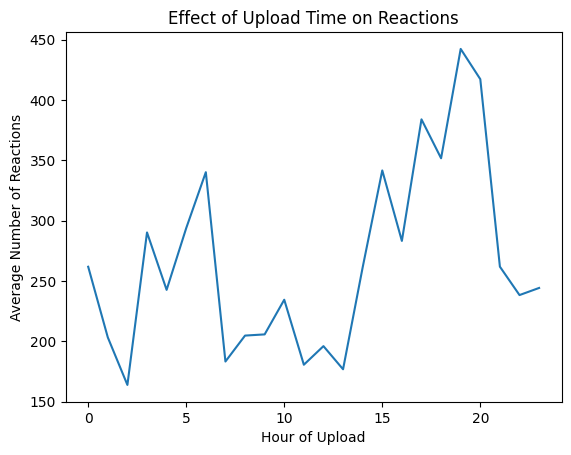

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/Facebook_Marketplace_data.csv")

df['status_published'] = pd.to_datetime(df['status_published'])

df['hour'] = df['status_published'].dt.hour

hourly_avg_reactions = df.groupby('hour')['num_reactions'].mean()

print(hourly_avg_reactions)

plt.figure()
plt.plot(hourly_avg_reactions.index, hourly_avg_reactions.values)
plt.xlabel("Hour of Upload")
plt.ylabel("Average Number of Reactions")
plt.title("Effect of Upload Time on Reactions")
plt.show()


2.	Is there a correlation between the number of reactions (num_reactions) and other engagement metrics such as comments (num_comments) and shares (num_shares)? If so, what is the strength and direction of this correlation?

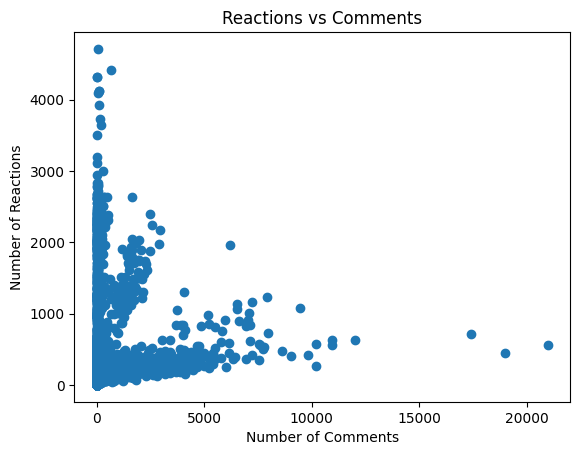

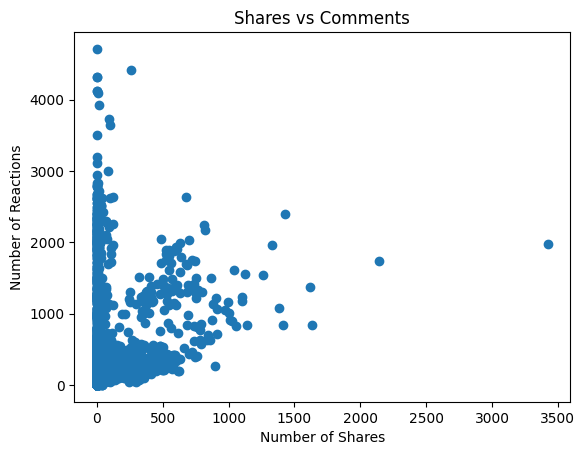

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/Facebook_Marketplace_data.csv")

plt.figure()
plt.scatter(df["num_comments"], df["num_reactions"])
plt.xlabel("Number of Comments")
plt.ylabel("Number of Reactions")
plt.title("Reactions vs Comments")
plt.show()

plt.figure()
plt.scatter(df["num_shares"], df["num_reactions"])
plt.xlabel("Number of Shares")
plt.ylabel("Number of Reactions")
plt.title("Shares vs Comments")
plt.show()

3.	Use the columns status_type, num_reactions, num_comments, num_shares, num_likes, num_loves, num_wows, num_hahas, num_sads, and num_angrys to train a K-Means clustering model on the Facebook Live Sellers dataset.
4.	Use the elbow method to find the optimum number of clusters.


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import pandas as pd

# Load dataset
df = pd.read_csv("data/Facebook_Marketplace_data.csv")

# Select features
features = ['status_type','num_reactions','num_comments',
            'num_shares','num_likes','num_loves',
            'num_wows','num_hahas','num_sads','num_angrys']

df_selected = df[features]

print(df_selected)

     status_type  num_reactions  num_comments  num_shares  num_likes  \
0          video            529           512         262        432   
1          photo            150             0           0        150   
2          video            227           236          57        204   
3          photo            111             0           0        111   
4          photo            213             0           0        204   
...          ...            ...           ...         ...        ...   
7045       photo             89             0           0         89   
7046       photo             16             0           0         14   
7047       photo              2             0           0          1   
7048       photo            351            12          22        349   
7049       photo             17             0           0         17   

      num_loves  num_wows  num_hahas  num_sads  num_angrys  
0            92         3          1         1           0  
1            

In [ ]:
import numpy as np
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans

df = pd.read_csv("data/Facebook_Marketplace_data.csv")
#X = df.iloc[:,[1,3,4,5,6,7,8,9,10,11]].values


features = ['status_type','num_reactions','num_comments',
            'num_shares','num_likes','num_loves',
            'num_wows','num_hahas','num_sads','num_angrys']

X = df[features]


df_encoded = pd.get_dummies(X, columns=['status_type'])


scaler = StandardScaler()
scaled_data = scaler.fit_transform(df_encoded)

print(scaled_data)


[[ 0.64610394  0.32335035  1.6868788  ... -1.24599285 -0.23366611
   1.42146599]
 [-0.17319166 -0.25220622 -0.3041444  ...  0.80257282 -0.23366611
  -0.70349907]
 [-0.00673846  0.01308938  0.12901714 ... -1.24599285 -0.23366611
   1.42146599]
 ...
 [-0.49312768 -0.25220622 -0.3041444  ...  0.80257282 -0.23366611
  -0.70349907]
 [ 0.26131603 -0.23871662 -0.13695924 ...  0.80257282 -0.23366611
  -0.70349907]
 [-0.46070173 -0.25220622 -0.3041444  ...  0.80257282 -0.23366611
  -0.70349907]]


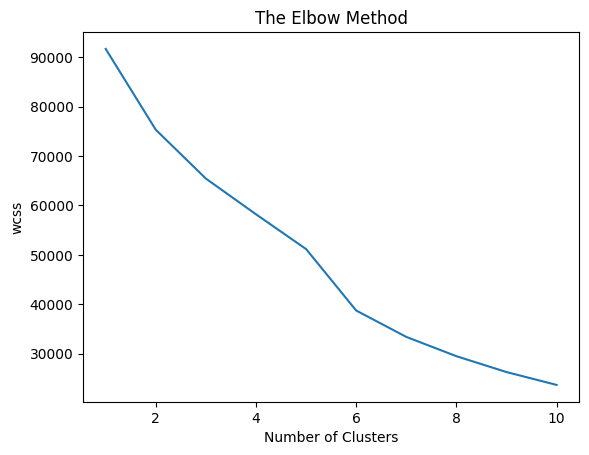

In [ ]:
wcss = []

for i in range(1,11):
  kmeans = KMeans(n_clusters= i, init = 'k-means++', random_state= 42)
  kmeans.fit(scaled_data)

  wcss.append(kmeans.inertia_)


plt.plot(range(1,11),wcss)
plt.title('The Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('wcss')
plt.show()

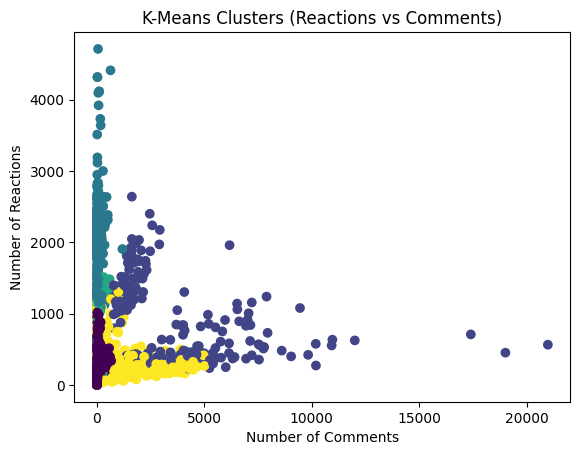

In [ ]:
kmeans = KMeans(n_clusters= 6, init = 'k-means++', random_state= 42)
y_kmeans = kmeans.fit_predict(scaled_data)

plt.figure()

plt.scatter(df['num_comments'],
            df['num_reactions'],
            c=y_kmeans)

plt.xlabel("Number of Comments")
plt.ylabel("Number of Reactions")
plt.title("K-Means Clusters (Reactions vs Comments)")

plt.show()



5.	What is the count of different types of posts in the dataset?
6.	What is the average value of num_reaction, num_comments, num_shares for each post type?


In [ ]:
import pandas as pd

df = pd.read_csv("data/Facebook_Marketplace_data.csv")

post_type_counts = df['status_type'].value_counts()
print("Count of Different Post Types:\n")
print(post_type_counts)

average_engagement = df.groupby('status_type')[['num_reactions',
                                                'num_comments',
                                                'num_shares']].mean()

print("\nAverage Engagement per Post Type:\n")
print(average_engagement.round(2))


Count of Different Post Types:

status_type
photo     4288
video     2334
status     365
link        63
Name: count, dtype: int64

Average Engagement per Post Type:

             num_reactions  num_comments  num_shares
status_type                                         
link                370.14          5.70        4.40
photo               181.29         15.99        2.55
status              438.78         36.24        2.56
video               283.41        642.48      115.68
